# Design table generator – Experiment 3, tapping (v2, 216 trials)

Builds the randomized trial table for **one participant**, checks automatically that every count is exactly as designed, and illustrates with figures how **levels ↔ trials**, **counterbalancing** and **randomization** work.

**Trial anatomy (30 events, 450 ms onset-to-onset grid, 350 ms events)**

| Part | lead-in | S1 | A | S2 | B |
|---|---|---|---|---|---|
| Events (1-based) | 1–6 | 7–12 | 13–18 | 19–24 | 25–30 |
| Can be jittered | never | never | x2–x6 (events 14–18) | w2–w6 (events 20–24) | x2–x3 (events 26–27) |

- Jitter = **phase shift**: the jittered event and everything after it move by ±d.
- Interval *Ik* of a part = the gap before that part's event *k+1* → the first event of A, S2 and B is **never** moved.
- B only I1–I2: at least **3 events after** a B jitter.
- 2-jitter trials: the second jittered event is **≥ 6 events** after the first (= **5 clean events** in between).

**Design per participant (identical for both groups)**

| | |
|---|---|
| Items | 18 sentences × 3 types (2\|4, 3\|3, word list) = 54 items |
| Trials | 54 × 4 = **216** (72 per sentence type), ≈ 58 min tapping + breaks |
| Roles (each sentence gets each role once) | `critical_I2`, `critical_I3`, `filler`, `baseline` |
| Critical (per type × interval: 18) | 6 size×direction × 3 reps |
| Filler (per type: 18) | S2 jitter at I1 / I4 / I5 × 6 size×direction, 1 each |
| Baseline (per type: 18) | 15 no jitter + 3 noise+noise (A+B) |
| 2-jitter trials (per type: 15) | **6 critical + noise** (each size×direction once; per size one direction at I2, the other at I3) · **6 filler + noise** (each size×direction once; per filler interval 1 early + 1 late) · **3 A+B** |
| A vs B for the noise jitter (per type, fixed) | critical I2: 2 A + 1 B · critical I3: 3 A · filler I1: 1 A + 1 B · filler I4/I5: 2 A each → **10 A+S2, 2 S2+B, 3 A+B** |
| Jitter count | 0 / 1 / 2 = **15 / 42 / 15** per type (45 / 126 / 45 → 21 / 58 / 21 %) |
| Noise jitters (per type: 18) | 6 size×direction × 3; position random among the **legal** positions |
| Blocks | 9 × 24 trials; per block **2 trials per role per sentence type**; a sentence's 4 trials fall in 4 different blocks |
| Order | shuffled within blocks (participant-specific seed); never the same sentence twice in a row |

**What is fixed vs. random**
- *Fixed (counterbalanced)*: every count in the table above, per participant.
- *Random (new per participant)*: which sentence gets which size×direction, which size×direction gets the noise jitter at I2 vs I3 (and at which filler interval), which of those trials get B instead of A, the exact A/B interval (among legal positions), which block each trial goes to, and trial order.

**To use:** edit the settings cell → *Run All*. CSV is written to `design_tables/`.
Sentence IDs: `S24_01 … S24_18`, `S33_01 … S33_18`, `WL_01 … WL_18` – map them to your sound files.

## 1. Settings – the only cell you need to edit

In [1]:
PARTICIPANT_ID = "P01"
GROUP          = "speech"          # "speech" (informed SWS) or "acoustic" (naive SWS)
SEED           = None              # None -> derived from PARTICIPANT_ID (reproducible)

JITTER_SIZES_MS    = [15, 30, 50]  # PLACEHOLDERS – replace with your real sizes
MIN_EVENTS_BETWEEN = 6             # event-index distance between the 2 jittered events (6 = 5 clean events between)
IOI_MS             = 450           # onset-to-onset
EVENT_MS           = 350           # event duration
ITI_S              = 2.5           # pause between trials (only for the duration estimate)
OUTPUT_DIR         = "design_tables"

## 2. Fixed design constants

In [2]:
import zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

N_EVENTS         = 30
TRIAL_DURATION_S = N_EVENTS * IOI_MS / 1000          # 13.5 s

SENT_TYPES  = ["2|4", "3|3", "word list"]
TYPE_CODE   = {"2|4": "S24", "3|3": "S33", "word list": "WL"}
N_SENTENCES = 18                   # per sentence type
N_BLOCKS    = 9                    # 18 sentences / 9 blocks = 2 per role per block
INTERVALS   = ["I1", "I2", "I3", "I4", "I5"]
CRITICAL    = ["I2", "I3"]
S2_FILLER   = ["I1", "I4", "I5"]
DIRECTIONS  = ["early", "late"]
COMBOS      = [(s, d) for s in JITTER_SIZES_MS for d in DIRECTIONS]      # 6 size × direction levels
ROLES       = ["critical_I2", "critical_I3", "filler", "baseline"]

A_INTERVALS = INTERVALS            # A: I1–I5  (events 14–18)
B_INTERVALS = ["I1", "I2"]         # B: I1–I2  (events 26–27) -> at least 3 events after the jitter
BASELINE_PATTERNS = {"none": 15, "A+B": 3}
N_B_NOISE = {"I2": 1, "I1": 1}     # per sentence type: how many S2+noise trials put the noise in B (only I1, I2 allow B)
PATTERN_PARTS = {"none": [], "S2": ["S2"], "A+S2": ["A", "S2"], "S2+B": ["S2", "B"], "A+B": ["A", "B"]}

# 0-based event index of the first event of each part: lead-in 0–5, S1 6–11, A 12–17, S2 18–23, B 24–29.
# Interval Ik of a part = gap before that part's event k+1  ->  moved event index = offset + k.
PART_OFFSET = {"A": 12, "S2": 18, "B": 24}

def gap_index(part, interval):
    # 0-based index of the event that is moved by a jitter at `interval` of `part`
    return PART_OFFSET[part] + int(interval[1:])

def legal_noise(s2_interval):
    # all (part, interval) positions where a noise jitter may go, given the S2 jitter
    s = gap_index("S2", s2_interval)
    opts  = [("A", iv) for iv in A_INTERVALS if s - gap_index("A", iv) >= MIN_EVENTS_BETWEEN]
    opts += [("B", iv) for iv in B_INTERVALS if gap_index("B", iv) - s >= MIN_EVENTS_BETWEEN]
    return opts

for iv in INTERVALS:
    print(f"S2 jitter at {iv} (event {gap_index('S2', iv) + 1}): legal noise positions ->",
          [f"{p} {i} (event {gap_index(p, i) + 1})" for p, i in legal_noise(iv)])

S2 jitter at I1 (event 20): legal noise positions -> ['A I1 (event 14)', 'B I1 (event 26)', 'B I2 (event 27)']
S2 jitter at I2 (event 21): legal noise positions -> ['A I1 (event 14)', 'A I2 (event 15)', 'B I2 (event 27)']
S2 jitter at I3 (event 22): legal noise positions -> ['A I1 (event 14)', 'A I2 (event 15)', 'A I3 (event 16)']
S2 jitter at I4 (event 23): legal noise positions -> ['A I1 (event 14)', 'A I2 (event 15)', 'A I3 (event 16)', 'A I4 (event 17)']
S2 jitter at I5 (event 24): legal noise positions -> ['A I1 (event 14)', 'A I2 (event 15)', 'A I3 (event 16)', 'A I4 (event 17)', 'A I5 (event 18)']


## 3. Design generator

How every count is guaranteed **by construction** (per sentence type, 18 sentences):

| Role | Built from a fixed list of 18 "cells" | Randomized |
|---|---|---|
| `critical_I2` / `critical_I3` | 6 size×direction × 3 reps; 3 of the 18 carry a noise jitter (one per size; the direction at I2 is the opposite of the one at I3) | which sentence gets which cell; which direction goes to I2 vs I3 |
| `filler` | 3 intervals (I1/I4/I5) × 6 size×direction; 6 carry a noise jitter (each size×direction once, each filler interval 1 early + 1 late) | which sentence gets which cell; which sizes pair with which interval |
| noise in A or B | fixed numbers: `N_B_NOISE` (critical I2: 1 B, filler I1: 1 B), all others A | which trial gets B; exact interval drawn from `legal_noise()` |
| `baseline` | 15 × `none` + 3 × `A+B` | which sentence gets which; A interval (I1–I5) and B interval (I1–I2) |
| noise sizes | all 18 noise jitters of the type get 6 size×direction × 3 | which noise jitter gets which level |

The list of cells is **shuffled, not sampled** → counts are exact for every participant, only the item ↔ cell mapping changes.
Because noise positions are only drawn from legal positions, the spacing rule can never be violated (it is still checked in §5).

**Blocks:** each role deals its 18 sentences 2 per block; then sentences are swapped *within a role* until every sentence has its 4 trials in 4 different blocks (swaps keep the 2-per-block counts).

In [3]:
def _assign_blocks(sids, rng):
    # (sentence, role) -> block; 2 sentences per role per block; 4 different blocks per sentence
    place = {}
    for role in ROLES:
        for j, s in enumerate(rng.permutation(len(sids))):
            place[(sids[s], role)] = j % N_BLOCKS
    clash = lambda s: len(ROLES) - len({place[(s, r)] for r in ROLES})
    total = sum(clash(s) for s in sids)
    for _ in range(200_000):
        if total == 0:
            return place
        bad = [s for s in sids if clash(s)]
        s = bad[rng.integers(len(bad))]
        r = ROLES[rng.integers(len(ROLES))]
        o = sids[rng.integers(len(sids))]
        if o == s or place[(o, r)] == place[(s, r)]:
            continue
        before = clash(s) + clash(o)
        place[(s, r)], place[(o, r)] = place[(o, r)], place[(s, r)]
        after = clash(s) + clash(o)
        if after > before:
            place[(s, r)], place[(o, r)] = place[(o, r)], place[(s, r)]
        else:
            total += after - before
    raise RuntimeError("Block assignment failed")


def _place_noise(ts, n_b, rng):
    # give each trial in ts a noise jitter: n_b of them in B, the rest in A; interval random among legal ones
    for k, j in enumerate(rng.permutation(len(ts))):
        t = ts[j]
        part = "B" if k < n_b else "A"
        opts = [iv for p, iv in legal_noise(t["S2_interval"]) if p == part]
        assert opts, (t["S2_interval"], part)
        t["pattern"] = "A+S2" if part == "A" else "S2+B"
        t[f"{part}_interval"] = str(opts[rng.integers(len(opts))])


def _dist(t):
    parts = PATTERN_PARTS[t["pattern"]]
    if len(parts) < 2:
        return None
    g = sorted(gap_index(p, t[f"{p}_interval"]) for p in parts)
    return g[1] - g[0]


def make_design(participant_id, group, seed=None):
    if seed is None:
        seed = zlib.crc32(participant_id.encode())
    rng = np.random.default_rng(seed)
    all_trials = []

    for st in SENT_TYPES:
        sids = [f"{TYPE_CODE[st]}_{i:02d}" for i in range(1, N_SENTENCES + 1)]
        trials = []
        base = lambda sid, role, pat: {"sentence_type": st, "sentence_id": sid, "role": role, "pattern": pat}

        # --- which size×direction carries an extra noise jitter (6 critical + 6 filler per type)
        crit_noise = {"I2": [], "I3": []}
        for s in JITTER_SIZES_MS:                       # per size: one direction at I2, the other at I3
            d = rng.permutation(DIRECTIONS)
            crit_noise["I2"].append((s, str(d[0])))
            crit_noise["I3"].append((s, str(d[1])))
        early, late = rng.permutation(JITTER_SIZES_MS), rng.permutation(JITTER_SIZES_MS)
        fill_noise = {iv: [(int(early[i]), "early"), (int(late[i]), "late")] for i, iv in enumerate(S2_FILLER)}

        # --- critical: 6 size×direction × 3 reps (one rep of the chosen levels carries noise)
        for role, iv in (("critical_I2", "I2"), ("critical_I3", "I3")):
            cells = [(c, rep == 0 and c in crit_noise[iv]) for c in COMBOS for rep in range(3)]   # 18
            new = []
            for sid, j in zip(sids, rng.permutation(len(cells))):
                combo, noise = cells[j]
                new.append(base(sid, role, "S2") | {"S2_interval": iv, "S2_combo": combo, "noise": noise})
            _place_noise([t for t in new if t["noise"]], N_B_NOISE.get(iv, 0), rng)
            trials += new

        # --- filler: 3 intervals × 6 size×direction, 1 each (6 of them carry noise)
        fcells = [(iv, c, c in fill_noise[iv]) for iv in S2_FILLER for c in COMBOS]           # 18
        new = []
        for sid, j in zip(sids, rng.permutation(len(fcells))):
            iv, c, noise = fcells[j]
            new.append(base(sid, "filler", "S2") | {"S2_interval": iv, "S2_combo": c, "noise": noise})
        for iv in S2_FILLER:
            _place_noise([t for t in new if t["noise"] and t["S2_interval"] == iv], N_B_NOISE.get(iv, 0), rng)
        trials += new

        # --- baseline: 15 none + 3 A+B
        bpats = [p for p, n in BASELINE_PATTERNS.items() for _ in range(n)]           # 18
        for sid, j in zip(sids, rng.permutation(len(bpats))):
            t = base(sid, "baseline", bpats[j])
            if bpats[j] == "A+B":
                t["A_interval"] = str(rng.choice(A_INTERVALS))
                t["B_interval"] = str(rng.choice(B_INTERVALS))
            trials.append(t)

        # --- noise sizes: all 18 noise jitters of this type get 6 size×direction × 3
        slots = [(t, p) for t in trials for p in ("A", "B") if p in PATTERN_PARTS[t["pattern"]]]
        assert len(slots) == 18
        for (t, p), j in zip(slots, rng.permutation(len(slots))):
            t[f"{p}_combo"] = COMBOS[j % 6]

        # --- blocks
        place = _assign_blocks(sids, rng)
        for t in trials:
            t["block"] = place[(t["sentence_id"], t["role"])] + 1
        all_trials += trials

    # --- order: shuffle within blocks; no sentence in two consecutive trials
    order = []
    for b in range(1, N_BLOCKS + 1):
        blk = [t for t in all_trials if t["block"] == b]
        for _ in range(10_000):
            blk = [blk[j] for j in rng.permutation(len(blk))]
            seq = ([order[-1]] if order else []) + blk
            if all(x["sentence_id"] != y["sentence_id"] for x, y in zip(seq, seq[1:])):
                break
        else:
            raise RuntimeError("Could not avoid back-to-back repeats")
        order += blk

    out, seen = [], {}
    for i, t in enumerate(order, start=1):
        parts = PATTERN_PARTS[t["pattern"]]
        seen[t["sentence_id"]] = seen.get(t["sentence_id"], 0) + 1
        r = {"participant": participant_id, "group": group, "seed": seed,
             "trial": i, "block": t["block"],
             "sentence_type": t["sentence_type"], "sentence_id": t["sentence_id"],
             "exposure": seen[t["sentence_id"]], "role": t["role"],
             "n_jitters": len(parts), "jitter_pattern": t["pattern"]}
        for part in ("A", "S2", "B"):
            on = part in parts
            size, direction = t[f"{part}_combo"] if on else (np.nan, None)
            r[f"{part}_jitter"] = on
            r[f"{part}_interval"] = t[f"{part}_interval"] if on else None
            r[f"{part}_event"] = gap_index(part, t[f"{part}_interval"]) + 1 if on else np.nan   # 1-based
            r[f"{part}_size_ms"] = size
            r[f"{part}_direction"] = direction
            r[f"{part}_shift_ms"] = (size if direction == "late" else -size) if on else 0
        r["S2_critical"] = t["role"].startswith("critical")
        r["S2_with_noise"] = "S2" in parts and len(parts) == 2
        r["critical_with_noise"] = r["S2_critical"] and r["S2_with_noise"]
        d = _dist(t)
        r["jitter_distance"] = d                                   # event-index distance (>= MIN_EVENTS_BETWEEN)
        r["clean_events_between"] = None if d is None else d - 1  # unjittered events between the two
        out.append(r)
    df = pd.DataFrame(out)
    df["S2_boundary_status"] = np.select(
        [~df.S2_critical, df.sentence_type == "word list",
         ((df.sentence_type == "2|4") & (df.S2_interval == "I2")) | ((df.sentence_type == "3|3") & (df.S2_interval == "I3"))],
        ["(not critical)", "no structure", "boundary"], default="within-phrase")
    return df

## 4. Build the table for this participant

In [4]:
df = make_design(PARTICIPANT_ID, GROUP, SEED)
print(f"{len(df)} trials, {df.sentence_id.nunique()} sentences, seed = {df.seed.iloc[0]}")
print(f"tapping time ≈ {len(df) * (TRIAL_DURATION_S + ITI_S) / 60:.1f} min "
      f"({N_BLOCKS} blocks × {len(df) // N_BLOCKS} trials, {(len(df) // N_BLOCKS) * (TRIAL_DURATION_S + ITI_S) / 60:.1f} min per block)")
df.head(12)

216 trials, 54 sentences, seed = 493207915
tapping time ≈ 57.6 min (9 blocks × 24 trials, 6.4 min per block)


,participant,group,seed,trial,block,sentence_type,sentence_id,exposure,role,n_jitters,...,B_event,B_size_ms,B_direction,B_shift_ms,S2_critical,S2_with_noise,critical_with_noise,jitter_distance,clean_events_between,S2_boundary_status
0,P01,speech,493207915,1,1,2|4,S24_17,1,critical_I3,1,...,NaN,NaN,NaN,0,True,False,False,NaN,NaN,within-phrase
1,P01,speech,493207915,2,1,3|3,S33_14,1,filler,1,...,NaN,NaN,NaN,0,False,False,False,NaN,NaN,(not critical)
2,P01,speech,493207915,3,1,2|4,S24_14,1,baseline,0,...,NaN,NaN,NaN,0,False,False,False,NaN,NaN,(not critical)
3,P01,speech,493207915,4,1,2|4,S24_08,1,critical_I3,1,...,NaN,NaN,NaN,0,True,False,False,NaN,NaN,within-phrase
4,P01,speech,493207915,5,1,2|4,S24_01,1,filler,1,...,NaN,NaN,NaN,0,False,False,False,NaN,NaN,(not critical)
5,P01,speech,493207915,6,1,word list,WL_01,1,critical_I2,1,...,NaN,NaN,NaN,0,True,False,False,NaN,NaN,no structure
6,P01,speech,493207915,7,1,word list,WL_13,1,filler,1,...,NaN,NaN,NaN,0,False,False,False,NaN,NaN,(not critical)
7,P01,speech,493207915,8,1,2|4,S24_15,1,critical_I2,1,...,NaN,NaN,NaN,0,True,False,False,NaN,NaN,boundary
8,P01,speech,493207915,9,1,3|3,S33_05,1,critical_I3,1,...,NaN,NaN,NaN,0,True,False,False,NaN,NaN,boundary
9,P01,speech,493207915,10,1,2|4,S24_11,1,critical_I2,1,...,NaN,NaN,NaN,0,True,False,False,NaN,NaN,boundary


## 5. Automatic balance checks
If any check fails, this cell stops with an error.

In [5]:
def _noise(d):
    a = d.loc[d.A_jitter, ["A_size_ms", "A_direction", "A_interval"]].set_axis(["size", "dir", "interval"], axis=1).assign(part="A")
    b = d.loc[d.B_jitter, ["B_size_ms", "B_direction", "B_interval"]].set_axis(["size", "dir", "interval"], axis=1).assign(part="B")
    return pd.concat([a, b], ignore_index=True)


def check_balance(df):
    assert len(df) == 216 and df.trial.is_unique
    for st in SENT_TYPES:
        d = df[df.sentence_type == st]
        assert len(d) == 72, st
        assert d.role.value_counts().to_dict() == {r: 18 for r in ROLES}, st
        assert d.n_jitters.value_counts().to_dict() == {0: 15, 1: 42, 2: 15}, st
        s2 = d[d.S2_jitter]
        assert s2.S2_interval.value_counts().to_dict() == {"I2": 18, "I3": 18, "I1": 6, "I4": 6, "I5": 6}, st
        crit = d[d.S2_critical]
        g = crit.groupby(["S2_interval", "S2_size_ms", "S2_direction"])
        assert len(g) == 12 and (g.size() == 3).all(), st                       # 3 reps per cell
        assert crit.S2_with_noise.sum() == 6, st
        assert (crit.groupby(["S2_size_ms", "S2_direction"]).S2_with_noise.sum() == 1).all(), st   # each level once
        assert (crit.groupby(["S2_interval", "S2_size_ms"]).S2_with_noise.sum() == 1).all(), st    # per interval 1 per size
        fl = d[d.role == "filler"]
        f = fl.groupby(["S2_interval", "S2_size_ms", "S2_direction"]).size()
        assert len(f) == 18 and (f == 1).all(), st                              # fillers fully crossed
        assert fl.S2_with_noise.sum() == 6, st
        assert (fl.groupby(["S2_size_ms", "S2_direction"]).S2_with_noise.sum() == 1).all(), st     # each level once
        assert (fl.groupby(["S2_interval", "S2_direction"]).S2_with_noise.sum() == 1).all(), st    # per interval 1 early + 1 late
        assert d.jitter_pattern.value_counts().to_dict() == {"S2": 42, "none": 15, "A+S2": 10, "A+B": 3, "S2+B": 2}, st
        base = d[d.role == "baseline"]
        assert base.jitter_pattern.value_counts().to_dict() == BASELINE_PATTERNS, st
        nz = _noise(d).groupby(["size", "dir"]).size()
        assert len(nz) == 6 and (nz == 3).all(), st                             # noise sizes balanced
    # legal positions
    assert df.loc[df.B_jitter, "B_interval"].isin(B_INTERVALS).all()
    assert df.loc[df.A_jitter, "A_interval"].isin(A_INTERVALS).all()
    assert (df.loc[df.n_jitters == 2, "jitter_distance"] >= MIN_EVENTS_BETWEEN).all(), "jitters too close"
    # sentences: 4 trials, one of each role, 4 different blocks
    g = df.groupby("sentence_id")
    assert (g.size() == 4).all() and (g.role.nunique() == 4).all() and (g.block.nunique() == 4).all()
    assert (df.groupby(["block", "sentence_type"]).size() == 8).all()
    assert (df.groupby(["block", "sentence_type", "role"]).size() == 2).all()
    assert (df.sentence_id.values[1:] != df.sentence_id.values[:-1]).all(), "sentence repeated back-to-back"
    print("✓ All balance checks passed")

check_balance(df)

✓ All balance checks passed


## 6. Summary tables

In [6]:
print("Trials per sentence type × role")
display(pd.crosstab(df.sentence_type, df.role, margins=True)[ROLES + ["All"]])
print("\nJitter pattern × role (all sentence types)")
display(pd.crosstab(df.jitter_pattern, df.role, margins=True)[ROLES + ["All"]])
print("\nTrials per sentence type × number of jitters")
display(pd.crosstab(df.sentence_type, df.n_jitters, margins=True))
print("\nExample: the 4 trials of the first 3 sentences")
display(df[df.sentence_id.isin(["S24_01", "S24_02", "S24_03"])]
        .sort_values(["sentence_id", "trial"])
        [["sentence_id", "trial", "block", "exposure", "role", "jitter_pattern",
          "S2_interval", "S2_size_ms", "S2_direction", "A_interval", "B_interval", "clean_events_between"]])

Trials per sentence type × role


role,critical_I2,critical_I3,filler,baseline,All
sentence_type,,,,,
2|4,18,18,18,18,72
3|3,18,18,18,18,72
word list,18,18,18,18,72
All,54,54,54,54,216



Jitter pattern × role (all sentence types)


role,critical_I2,critical_I3,filler,baseline,All
jitter_pattern,,,,,
A+B,0,0,0,9,9
A+S2,6,9,15,0,30
S2,45,45,36,0,126
S2+B,3,0,3,0,6
none,0,0,0,45,45
All,54,54,54,54,216



Trials per sentence type × number of jitters


n_jitters,0,1,2,All
sentence_type,,,,
2|4,15,42,15,72
3|3,15,42,15,72
word list,15,42,15,72
All,45,126,45,216



Example: the 4 trials of the first 3 sentences


,sentence_id,trial,block,exposure,role,jitter_pattern,S2_interval,S2_size_ms,S2_direction,A_interval,B_interval,clean_events_between
4,S24_01,5,1,1,filler,S2,I5,30.0,early,NaN,NaN,NaN
32,S24_01,33,2,2,baseline,A+B,NaN,NaN,NaN,I5,I1,7.0
143,S24_01,144,6,3,critical_I3,A+S2,I3,30.0,late,I3,NaN,5.0
145,S24_01,146,7,4,critical_I2,S2,I2,50.0,late,NaN,NaN,NaN
82,S24_02,83,4,1,baseline,none,NaN,NaN,NaN,NaN,NaN,NaN
119,S24_02,120,5,2,critical_I2,S2,I2,15.0,late,NaN,NaN,NaN
148,S24_02,149,7,3,critical_I3,S2,I3,30.0,early,NaN,NaN,NaN
195,S24_02,196,9,4,filler,S2,I4,30.0,late,NaN,NaN,NaN
45,S24_03,46,2,1,baseline,none,NaN,NaN,NaN,NaN,NaN,NaN
114,S24_03,115,5,2,critical_I3,S2,I3,15.0,late,NaN,NaN,NaN


## 7. Figures

In [7]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})
ST_COLORS   = {"2|4": "#2a78d6", "3|3": "#eb6834", "word list": "#1baf7a"}
ROLE_COLORS = {"critical_I2": "#0b0b0b", "critical_I3": "#6250d6", "filler": "#9cc2ef", "baseline": "#c3c2b7"}
PART_COLORS = {"lead-in": "#d9d8d2", "S1": "#c9c8c0", "A": "#9cc2ef", "S2": "#f2b38f", "B": "#9cc2ef"}
INK = "#0b0b0b"
ROLE_SHORT = ["I2", "I3", "filler", "base"]


def grouped_bars(ax, table, title, xlabel, colors=ST_COLORS, ylabel="Trials"):
    n = len(table.columns); w = 0.8 / n
    x = np.arange(len(table.index))
    for i, c in enumerate(table.columns):
        bars = ax.bar(x + (i - (n - 1) / 2) * w, table[c], w * 0.92,
                      color=colors[c], label=c, edgecolor="white", linewidth=1)
        ax.bar_label(bars, fontsize=8, color="#52514e", padding=1)
    ax.set_xticks(x, table.index)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(table.values.max(), 1) * 1.35)


def count_heatmap(ax, table, title, vmax=None, fmt=None):
    vmax = vmax or max(table.values.max(), 1) * 1.3
    ax.imshow(table.values.astype(float), cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    for (i, j), v in np.ndenumerate(table.values):
        ax.text(j, i, fmt(i, j, v) if fmt else int(v), ha="center", va="center", fontsize=9,
                color="white" if v > vmax * 0.6 else INK)
    ax.set_xticks(range(table.shape[1]), table.columns, fontsize=8)
    ax.set_yticks(range(table.shape[0]), table.index, fontsize=8)
    ax.grid(False); ax.set_title(title, loc="left", fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)


def size_dir_table(d, size_col="S2_size_ms", dir_col="S2_direction"):
    t = pd.crosstab(d[size_col], d[dir_col]).reindex(index=JITTER_SIZES_MS, columns=DIRECTIONS, fill_value=0)
    t.index = [f"{s} ms" for s in t.index]
    return t

### 7.1 Trial anatomy: which events can be jittered
Top: the 30 events of a trial. **Grey hatched** = never jittered (lead-in, S1, and the first event of A, S2, B). **Coloured** = jitterable; the two critical S2 events are outlined. B only events 26–27 (≥ 3 events must follow).
Bottom: an example **A+S2** trial – a phase shift moves the jittered event *and everything after it*.

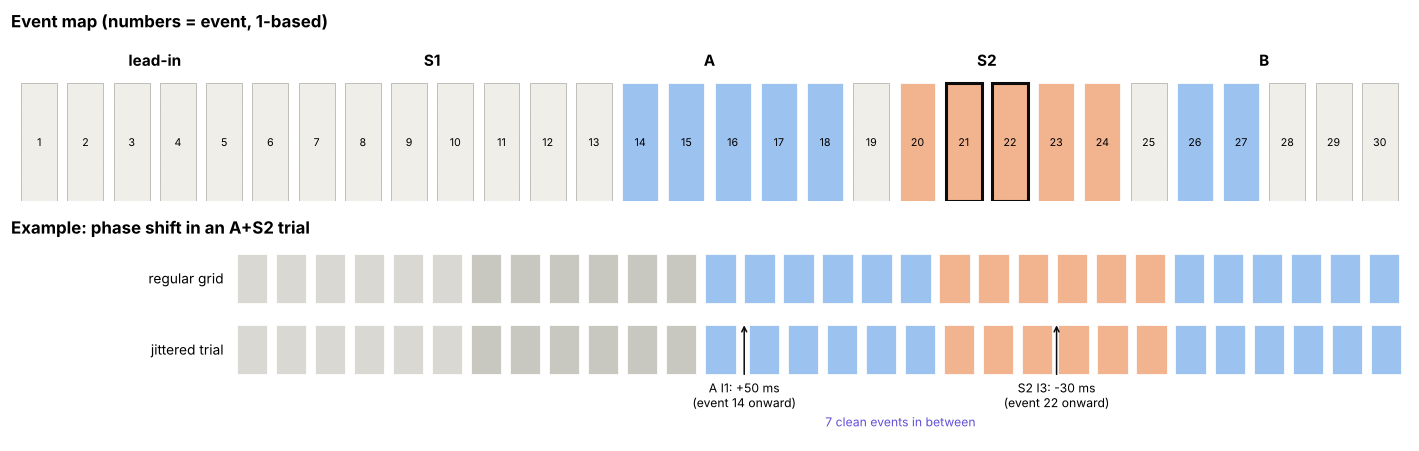

In [8]:
parts = [("lead-in", 0), ("S1", 6), ("A", 12), ("S2", 18), ("B", 24)]
jitterable = {gap_index(p, iv) for p, ivs in (("A", A_INTERVALS), ("S2", INTERVALS), ("B", B_INTERVALS)) for iv in ivs}
critical_ev = {gap_index("S2", iv) for iv in CRITICAL}

fig, axes = plt.subplots(2, 1, figsize=(13, 4.2), gridspec_kw={"height_ratios": [1, 1.2]})
ax = axes[0]
for name, off in parts:
    for k in range(6):
        e = off + k
        on = e in jitterable
        ax.add_patch(Rectangle((e * IOI_MS, 0), EVENT_MS, 1, color=PART_COLORS[name] if on else "#efeee9",
                               hatch=None if on else "///", ec="#b0afa8" if not on else "white", lw=0.5))
        if e in critical_ev:
            ax.add_patch(Rectangle((e * IOI_MS, 0), EVENT_MS, 1, fill=False, ec=INK, lw=2))
        ax.text(e * IOI_MS + EVENT_MS / 2, 0.5, e + 1, ha="center", va="center", fontsize=7)
    ax.text(off * IOI_MS + 3 * IOI_MS - 50, 1.15, name, ha="center", fontsize=10, fontweight="bold")
ax.set_xlim(-100, N_EVENTS * IOI_MS); ax.set_ylim(0, 1.4); ax.axis("off")
ax.set_title("Event map (numbers = event, 1-based)", loc="left")

# example A+S2: A I1 (event 14) +50 ms, S2 I3 (event 22) -30 ms
ax = axes[1]
shifts = np.zeros(N_EVENTS)
ex = [("A", "I1", +50), ("S2", "I3", -30)]
for p, iv, d in ex:
    shifts[gap_index(p, iv):] += d
for row, (lab, sh) in enumerate([("regular grid", np.zeros(N_EVENTS)), ("jittered trial", shifts)]):
    y = 1.3 - row * 1.3
    for name, off in parts:
        for k in range(6):
            e = off + k
            ax.add_patch(Rectangle((e * IOI_MS + sh[e], y), EVENT_MS, 0.9, color=PART_COLORS[name], ec="white", lw=0.5))
    ax.text(-150, y + 0.45, lab, ha="right", va="center", fontsize=9)
for p, iv, d in ex:
    e = gap_index(p, iv)
    ax.annotate(f"{p} {iv}: {d:+d} ms\n(event {e + 1} onward)", xy=(e * IOI_MS, 0.95), xytext=(e * IOI_MS, -0.6),
                ha="center", fontsize=8, arrowprops=dict(arrowstyle="->", color=INK))
e1, e2 = gap_index("A", "I1"), gap_index("S2", "I3")
ax.text((e1 + e2) / 2 * IOI_MS, -0.95, f"{e2 - e1 - 1} clean events in between", ha="center", fontsize=8, color="#6250d6")
ax.set_xlim(-2600, N_EVENTS * IOI_MS); ax.set_ylim(-1.2, 2.4); ax.axis("off")
ax.set_title("Example: phase shift in an A+S2 trial", loc="left")
plt.tight_layout(); plt.show()

### 7.2 Spacing rule: where can the second jitter go?
Rows = position of the S2 jitter; columns = possible noise jitter position. **Green** = legal (≥ 6 events apart, i.e. ≥ 5 clean events between), **numbers** = clean events between.
→ With a critical jitter at **I2** the noise jitter can be A I1, A I2 or B I2; at **I3** only A I1–I3 (B is never legal after I3).
→ Filler I1 allows A I1 or B I1–I2; fillers I4/I5 only A. **A+B** (baseline) is always legal.
→ Fixed per sentence type: S2+B in 1 critical-I2 and 1 filler-I1 trial, all other S2+noise trials use A.

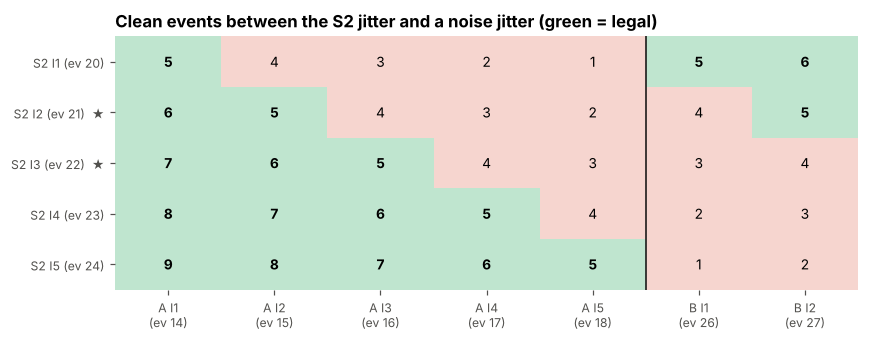

In [9]:
cols = [("A", iv) for iv in A_INTERVALS] + [("B", iv) for iv in B_INTERVALS]
M = np.array([[abs(gap_index("S2", s) - gap_index(p, iv)) for p, iv in cols] for s in INTERVALS])
legal = M >= MIN_EVENTS_BETWEEN
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.imshow(legal, cmap=ListedColormap(["#f6d5cf", "#bfe5cf"]), aspect="auto")
for (i, j), v in np.ndenumerate(M):
    ax.text(j, i, v - 1, ha="center", va="center", fontsize=9, fontweight="bold" if legal[i, j] else "normal")
ax.set_xticks(range(len(cols)), [f"{p} {iv}\n(ev {gap_index(p, iv) + 1})" for p, iv in cols], fontsize=8)
ax.set_yticks(range(5), [f"S2 {s} (ev {gap_index('S2', s) + 1})" + ("  ★" if s in CRITICAL else "") for s in INTERVALS], fontsize=8)
ax.axvline(4.5, color=INK, lw=1)
ax.grid(False); ax.set_title("Clean events between the S2 jitter and a noise jitter (green = legal)", loc="left")
for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.show()

### 7.3 How the factors map onto the critical trials (the main contrast)
Each critical interval is crossed with sentence type, so **boundary status** is fully crossed with **serial position**. Each cell = 18 trials (6 size×direction × 3 reps). Numbers come from the generated table.

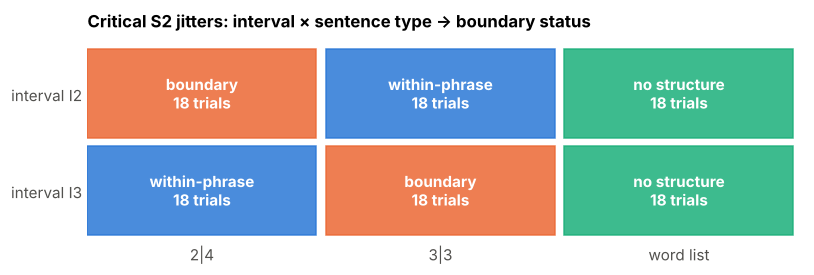

S2_boundary_status
within-phrase    36
no structure     36
boundary         36


In [10]:
crit = df[df.S2_critical]
t = pd.crosstab(crit.S2_interval, crit.sentence_type)[SENT_TYPES]
status = crit.groupby(["S2_interval", "sentence_type"]).S2_boundary_status.first().unstack()[SENT_TYPES]
SC = {"boundary": "#eb6834", "within-phrase": "#2a78d6", "no structure": "#1baf7a"}
fig, ax = plt.subplots(figsize=(7.5, 2.6))
for i, iv in enumerate(t.index):
    for j, st in enumerate(SENT_TYPES):
        s = status.loc[iv, st]
        ax.add_patch(Rectangle((j, -i - 1), 0.96, 0.92, color=SC[s], alpha=0.85))
        ax.text(j + 0.48, -i - 0.54, f"{s}\n{t.loc[iv, st]} trials", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
ax.set_xlim(0, 3); ax.set_ylim(-2.05, 0.05)
ax.set_xticks(np.arange(3) + 0.48, SENT_TYPES); ax.set_yticks([-0.54, -1.54], [f"interval {iv}" for iv in t.index])
ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Critical S2 jitters: interval × sentence type → boundary status", loc="left")
plt.tight_layout(); plt.show()
print(crit.S2_boundary_status.value_counts().to_string())

### 7.4 Every sentence: its 4 roles and the block each falls in
One row per sentence, one column per role; the number is the **block** (1–9). **Check:** every row is complete and has 4 different block numbers; every block number appears exactly twice per column.

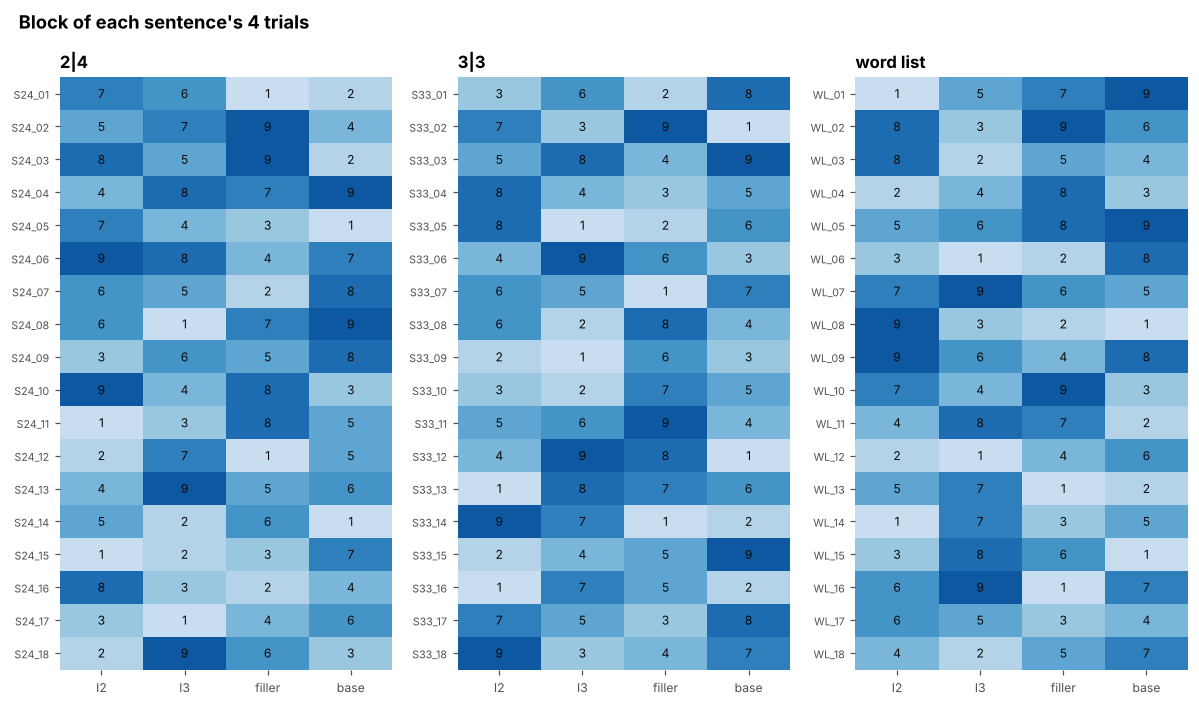

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5))
for ax, st in zip(axes, SENT_TYPES):
    d = df[df.sentence_type == st]
    t = d.pivot(index="sentence_id", columns="role", values="block")[ROLES]
    ax.imshow(t.values, cmap="Blues", vmin=-2, vmax=N_BLOCKS + 2, aspect="auto")
    for (i, j), v in np.ndenumerate(t.values):
        ax.text(j, i, int(v), ha="center", va="center", fontsize=8, color=INK)
    ax.set_xticks(range(4), ROLE_SHORT, fontsize=8)
    ax.set_yticks(range(len(t)), t.index, fontsize=7)
    ax.grid(False); ax.set_title(st, loc="left")
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle("Block of each sentence's 4 trials", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### 7.5 Every sentence: what happens in each of its 4 trials
Same layout as 7.4, but the cell shows the **condition** the sentence got in that role (size in ms, ↑ late / ↓ early, `+A`/`+B` = extra noise jitter). This mapping is what the randomization changes from participant to participant (see 7.13).

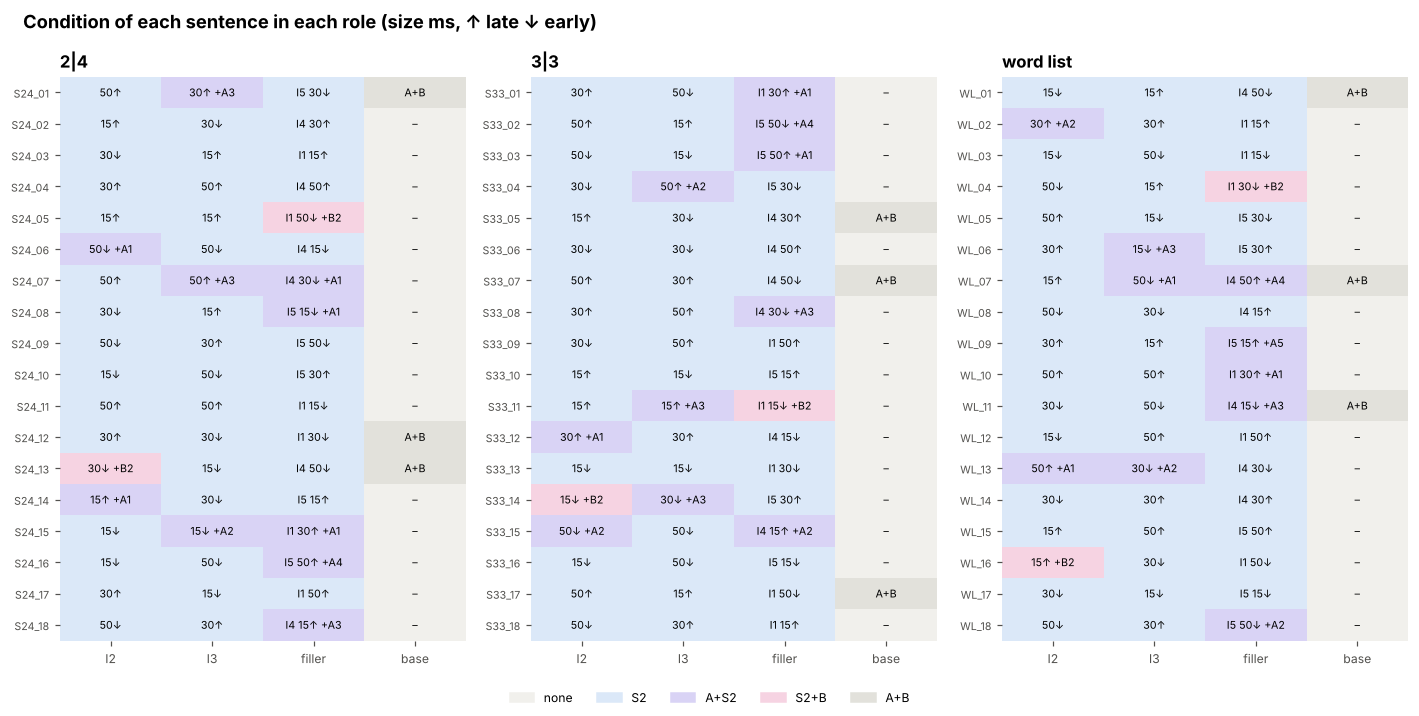

In [12]:
def label(r):
    if r.role == "baseline":
        return "A+B" if r.jitter_pattern == "A+B" else "–"
    arrow = "↑" if r.S2_direction == "late" else "↓"
    s = f"{int(r.S2_size_ms)}{arrow}"
    if r.role == "filler":
        s = f"{r.S2_interval} {s}"
    if r.jitter_pattern == "A+S2": s += f" +A{r.A_interval[1]}"
    if r.jitter_pattern == "S2+B": s += f" +B{r.B_interval[1]}"
    return s

ROLE_IDX = {r: i for i, r in enumerate(ROLES)}
fig, axes = plt.subplots(1, 3, figsize=(13, 6.5))
for ax, st in zip(axes, SENT_TYPES):
    d = df[df.sentence_type == st].copy()
    d["lab"] = d.apply(label, axis=1)
    sids = sorted(d.sentence_id.unique())
    colors = np.ones((len(sids), 4, 3))
    for _, r in d.iterrows():
        i, j = sids.index(r.sentence_id), ROLE_IDX[r.role]
        c = {"none": "#f1f0ec", "S2": "#dbe8f8", "A+S2": "#d9d3f5", "S2+B": "#f6d3e2", "A+B": "#e2e1db"}[r.jitter_pattern]
        colors[i, j] = [int(c[k:k + 2], 16) / 255 for k in (1, 3, 5)]
        ax.text(j, i, r.lab, ha="center", va="center", fontsize=7)
    ax.imshow(colors, aspect="auto")
    ax.set_xticks(range(4), ROLE_SHORT, fontsize=8); ax.set_yticks(range(len(sids)), sids, fontsize=7)
    ax.grid(False); ax.set_title(st, loc="left")
    for s in ax.spines.values(): s.set_visible(False)
handles = [Rectangle((0, 0), 1, 1, color=c) for c in ["#f1f0ec", "#dbe8f8", "#d9d3f5", "#f6d3e2", "#e2e1db"]]
fig.legend(handles, ["none", "S2", "A+S2", "S2+B", "A+B"], loc="lower center", ncols=5, fontsize=8)
fig.suptitle("Condition of each sentence in each role (size ms, ↑ late ↓ early)", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

### 7.6 Jitter pattern within each role
**Check:** identical for every sentence type – critical I2: 15 S2 + 2 A+S2 + 1 S2+B; critical I3: 15 S2 + 3 A+S2; filler: 12 S2 + 5 A+S2 + 1 S2+B; baseline: 15 none + 3 A+B.

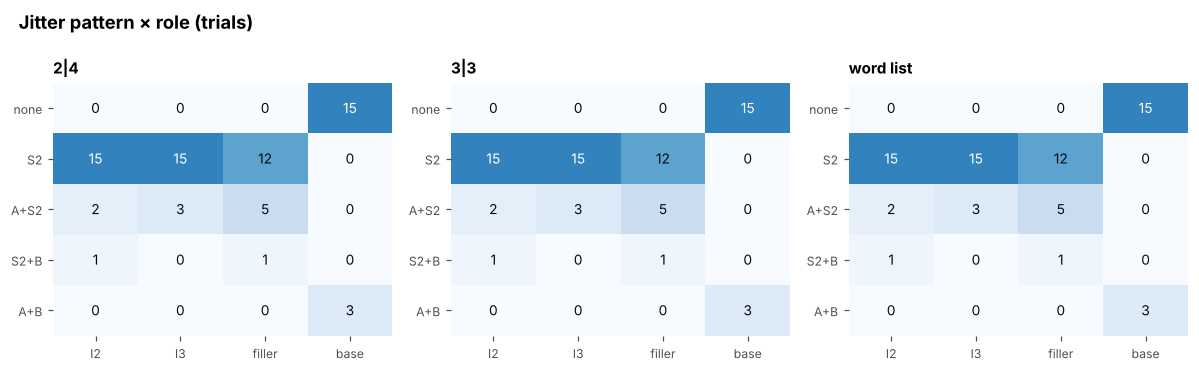

In [13]:
porder = ["none", "S2", "A+S2", "S2+B", "A+B"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, st in zip(axes, SENT_TYPES):
    d = df[df.sentence_type == st]
    t = pd.crosstab(d.jitter_pattern, d.role).reindex(index=porder, columns=ROLES, fill_value=0)
    t.columns = ROLE_SHORT
    count_heatmap(ax, t, st, vmax=22)
fig.suptitle("Jitter pattern × role (trials)", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### 7.7 Jitter count per sentence type
**Check:** 15 / 42 / 15 in every sentence type (≈ 21 / 58 / 21 %).

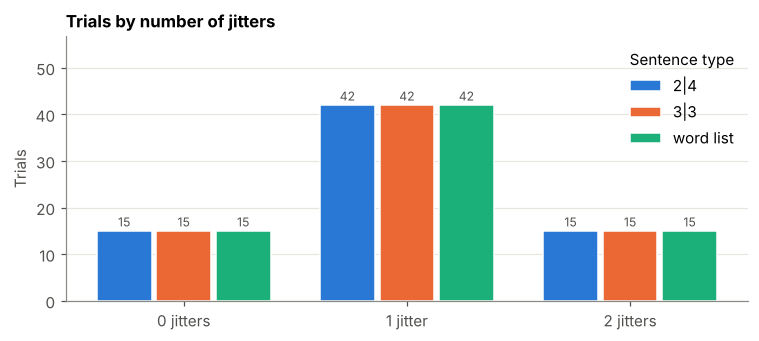

In [14]:
t = pd.crosstab(df.n_jitters, df.sentence_type)[SENT_TYPES]
t.index = [f"{i} jitter{'s' if i != 1 else ''}" for i in t.index]
fig, ax = plt.subplots(figsize=(7, 3.2))
grouped_bars(ax, t, "Trials by number of jitters", "")
ax.legend(title="Sentence type", loc="upper right")
plt.tight_layout(); plt.show()

### 7.8 Where the S2 jitter falls
**Check:** I2 = I3 = 18 (critical, shaded), I1 = I4 = I5 = 6 in every sentence type.

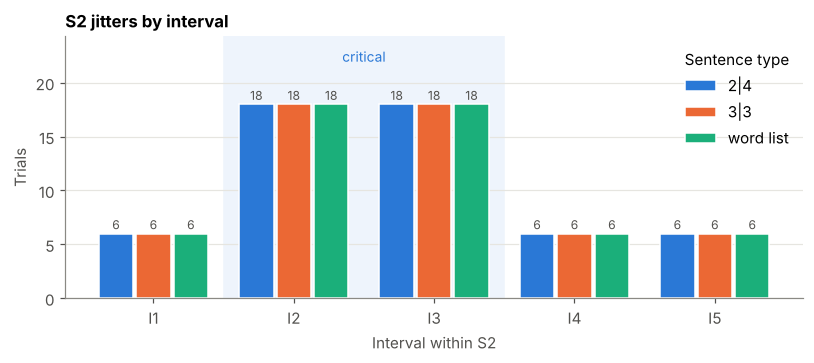

In [15]:
s2 = df[df.S2_jitter]
t = pd.crosstab(s2.S2_interval, s2.sentence_type).reindex(INTERVALS)[SENT_TYPES]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.axvspan(0.5, 2.5, color="#eef4fc", zorder=0)
grouped_bars(ax, t, "S2 jitters by interval", "Interval within S2")
ax.text(1.5, t.values.max() * 1.22, "critical", ha="center", color="#2a78d6", fontsize=9)
ax.legend(title="Sentence type", loc="upper right")
plt.tight_layout(); plt.show()

### 7.9 Critical trials: size × direction (counterbalancing of the main factor)
Each cell shows **total trials (of which with a noise jitter)**. **Check:** every cell has **3** trials. The noise jitter: each size × direction has it **once per sentence type**, at I2 *or* I3 (so read the I2 and I3 panels together: for each size, one direction has (1) at I2 and the other at I3).

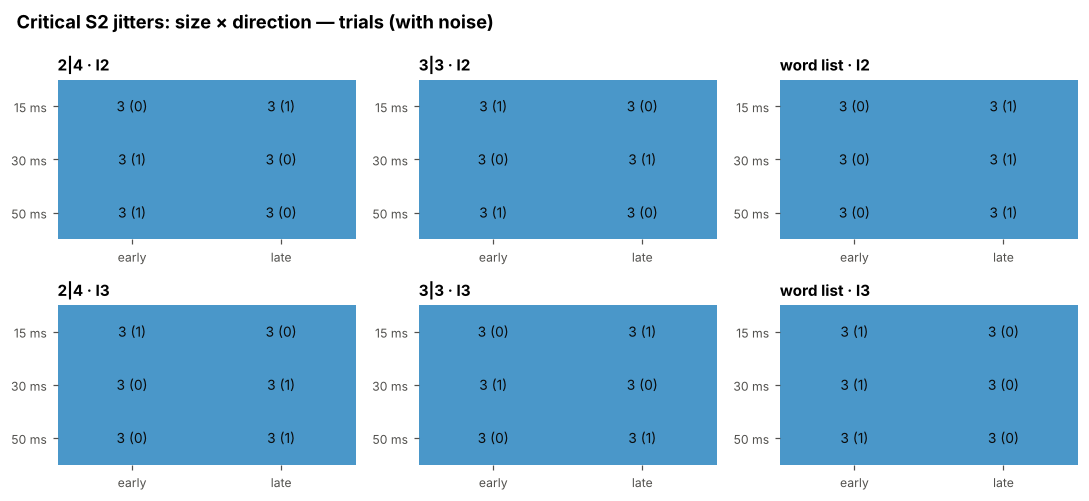

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(10, 4.6))
for c, st in enumerate(SENT_TYPES):
    d = crit[crit.sentence_type == st]
    for r, iv in enumerate(CRITICAL):
        sub = d[d.S2_interval == iv]
        tot = size_dir_table(sub)
        wn = size_dir_table(sub[sub.critical_with_noise]).reindex_like(tot).fillna(0)
        count_heatmap(axes[r, c], tot, f"{st} · {iv}", vmax=5, fmt=lambda i, j, v, wn=wn: f"{int(v)} ({int(wn.values[i, j])})")
fig.suptitle("Critical S2 jitters: size × direction — trials (with noise)", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### 7.10 Filler trials: interval × size × direction
**Check:** every cell = 1 → fillers are fully crossed (3 intervals × 6 levels = 18 per sentence type). Cells marked **+A / +B** also carry a noise jitter: each size×direction once, each interval 1 early + 1 late.

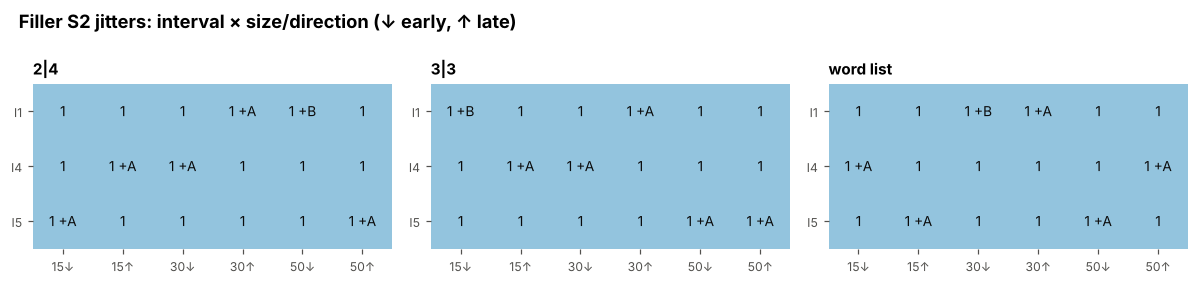

In [17]:
fill = df[(df.role == "filler")].copy()
fill["level"] = fill.S2_size_ms.astype(int).astype(str) + np.where(fill.S2_direction == "late", "↑", "↓")
levels = [f"{s}{a}" for s in JITTER_SIZES_MS for a in ("↓", "↑")]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.6))
for ax, st in zip(axes, SENT_TYPES):
    d = fill[fill.sentence_type == st]
    t = pd.crosstab(d.S2_interval, d.level).reindex(index=S2_FILLER, columns=levels, fill_value=0)
    nz = {(r.S2_interval, r.level): ("+A" if r.jitter_pattern == "A+S2" else "+B") for r in d[d.S2_with_noise].itertuples()}
    count_heatmap(ax, t, st, vmax=2.5,
                  fmt=lambda i, j, v, t=t, nz=nz: f"{int(v)} {nz.get((t.index[i], t.columns[j]), '')}".strip())
fig.suptitle("Filler S2 jitters: interval × size/direction (↓ early, ↑ late)", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### 7.11 Noise jitters (the between-group tapping baseline)
Left: size × direction per sentence type – **check: 3 per cell** (18 noise jitters per type). Right: where they fall. A vs B is **fixed** (per type: 13 A, 5 B); the exact interval is random among legal positions, so it is not flat: B only I1–I2, and A leans to early intervals because a noise jitter in A must stay ≥ 6 events before the S2 jitter.

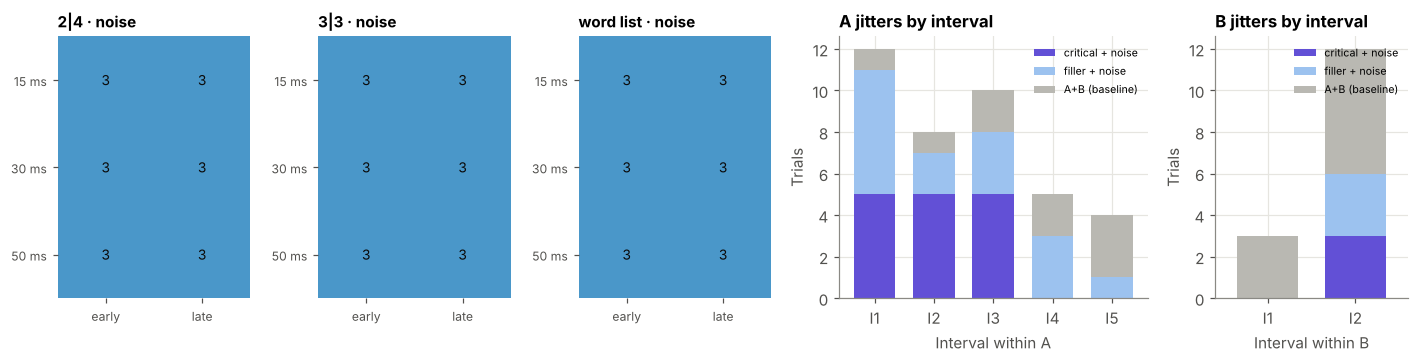

In [18]:
fig = plt.figure(figsize=(13, 3.4))
gs = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1.6, 1.0])
for c, st in enumerate(SENT_TYPES):
    ax = fig.add_subplot(gs[0, c])
    count_heatmap(ax, size_dir_table(_noise(df[df.sentence_type == st]), "size", "dir"), f"{st} · noise", vmax=5)
for k, part, ivs in ((3, "A", A_INTERVALS), (4, "B", B_INTERVALS)):
    ax = fig.add_subplot(gs[0, k])
    d = df[df[f"{part}_jitter"]]
    src = np.select([d.role == "baseline", d.role == "filler"], ["A+B (baseline)", "filler + noise"], "critical + noise")
    t = pd.crosstab(d[f"{part}_interval"], src).reindex(ivs, fill_value=0)
    SRC_C = {"critical + noise": "#6250d6", "filler + noise": "#9cc2ef", "A+B (baseline)": "#b9b8b2"}
    t = t[[c for c in SRC_C if c in t]]
    t.plot.bar(stacked=True, ax=ax, color=[SRC_C[c] for c in t], rot=0, width=0.7)
    ax.set_title(f"{part} jitters by interval", loc="left"); ax.set_xlabel(f"Interval within {part}"); ax.set_ylabel("Trials")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### 7.12 Spread over blocks
**Check:** every block has 8 trials per sentence type and **2 trials of each role per sentence type** (= 6 per role per block).

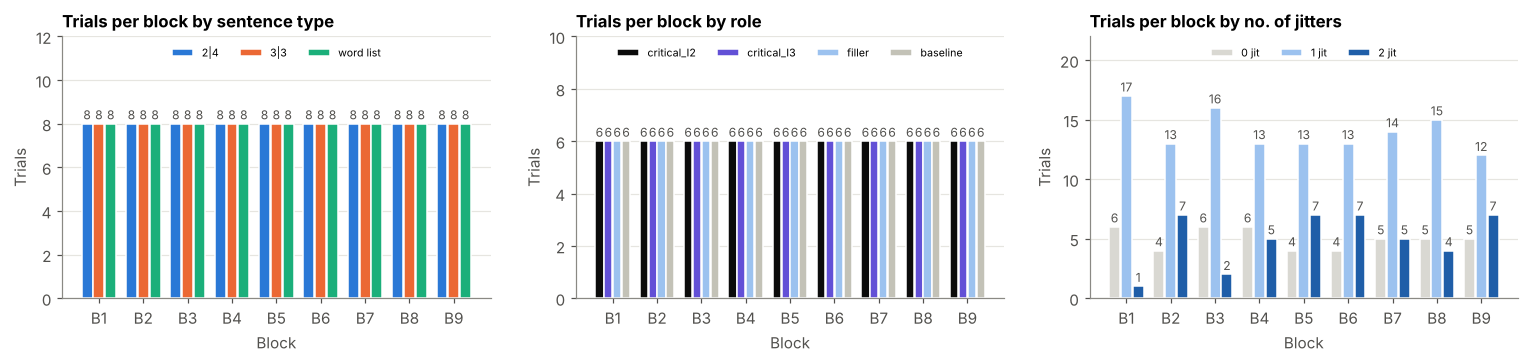

Jitter count per block is NOT fixed (only roles are) – it varies a little because the noise jitters are spread randomly.


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
t = pd.crosstab(df.block, df.sentence_type)[SENT_TYPES]; t.index = [f"B{b}" for b in t.index]
grouped_bars(axes[0], t, "Trials per block by sentence type", "Block")
axes[0].set_ylim(0, 12); axes[0].legend(ncols=3, loc="upper center", fontsize=7)
t = pd.crosstab(df.block, df.role)[ROLES]; t.index = [f"B{b}" for b in t.index]
grouped_bars(axes[1], t, "Trials per block by role", "Block", colors=ROLE_COLORS)
axes[1].set_ylim(0, 10); axes[1].legend(ncols=4, loc="upper center", fontsize=7)
t = pd.crosstab(df.block, df.n_jitters); t.index = [f"B{b}" for b in t.index]; t.columns = [f"{c} jit" for c in t.columns]
grouped_bars(axes[2], t, "Trials per block by no. of jitters", "Block",
             colors={"0 jit": "#d9d8d2", "1 jit": "#9cc2ef", "2 jit": "#1f5ea8"})
axes[2].set_ylim(0, 22); axes[2].legend(ncols=3, loc="upper center", fontsize=7)
plt.tight_layout(); plt.show()
print("Jitter count per block is NOT fixed (only roles are) – it varies a little because the noise jitters are spread randomly.")

### 7.13 Which hearing of a sentence each role falls on
`exposure` = 1st–4th trial with that sentence. **Check:** critical I2 and I3 are spread similarly over exposures, so familiarity does not differ systematically between boundary and within-phrase positions (random per participant, so not exactly equal; balances over participants).

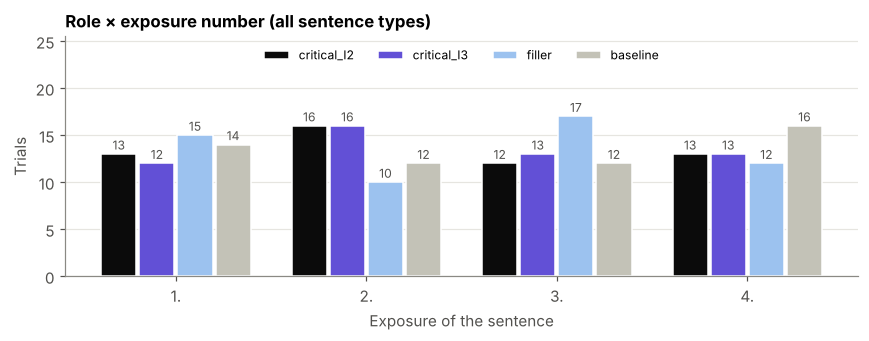

In [20]:
t = pd.crosstab(df.exposure, df.role)[ROLES]; t.index = [f"{e}." for e in t.index]
fig, ax = plt.subplots(figsize=(8, 3.2))
grouped_bars(ax, t, "Role × exposure number (all sentence types)", "Exposure of the sentence", colors=ROLE_COLORS)
ax.set_ylim(0, t.values.max() * 1.5); ax.legend(ncols=4, loc="upper center", fontsize=8)
plt.tight_layout(); plt.show()

### 7.14 The randomized trial sequence
One column per trial in presentation order; dashed lines = breaks. **Check:** no visible clustering.

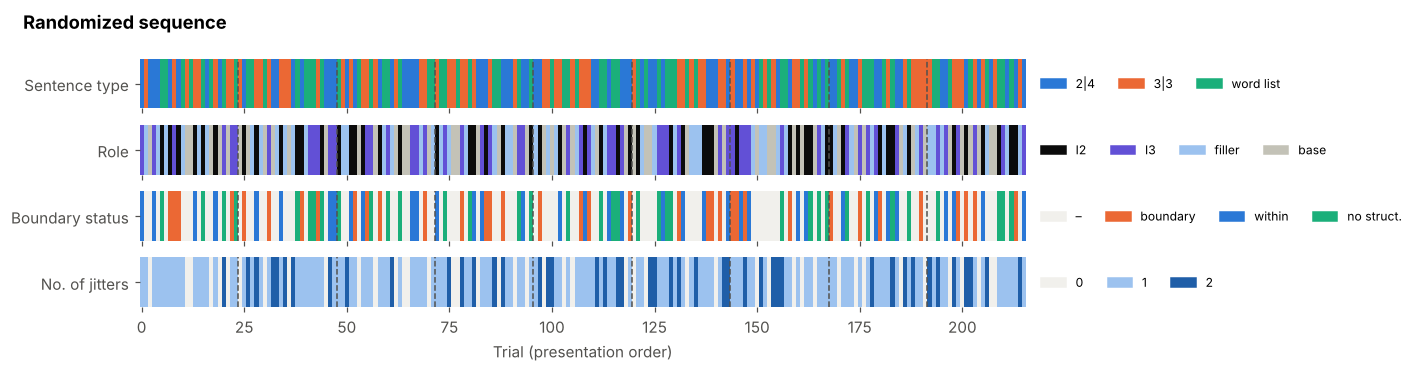

In [21]:
fig, axes = plt.subplots(4, 1, figsize=(13, 3.4), sharex=True)
stat_order = ["(not critical)", "boundary", "within-phrase", "no structure"]
rows = [("Sentence type", df.sentence_type.map({s: i for i, s in enumerate(SENT_TYPES)}), [ST_COLORS[s] for s in SENT_TYPES], SENT_TYPES),
        ("Role", df.role.map(ROLE_IDX), [ROLE_COLORS[r] for r in ROLES], ROLE_SHORT),
        ("Boundary status", df.S2_boundary_status.map({s: i for i, s in enumerate(stat_order)}),
         ["#f1f0ec", "#eb6834", "#2a78d6", "#1baf7a"], ["–", "boundary", "within", "no struct."]),
        ("No. of jitters", df.n_jitters, ["#f1f0ec", "#9cc2ef", "#1f5ea8"], ["0", "1", "2"])]
bounds = np.flatnonzero(np.diff(df.block.values)) + 1
for ax, (lab, vals, cols, names) in zip(axes, rows):
    ax.imshow(vals.values[None, :], aspect="auto", cmap=ListedColormap(cols), vmin=0, vmax=len(names) - 1, interpolation="nearest")
    ax.set_yticks([0], [lab]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    for b in bounds: ax.axvline(b - 0.5, color="#52514e", ls="--", lw=1)
    handles = [Rectangle((0, 0), 1, 1, color=c) for c in cols]
    ax.legend(handles, names, loc="center left", bbox_to_anchor=(1.005, 0.5), fontsize=8, ncols=len(names))
axes[-1].set_xlabel("Trial (presentation order)")
fig.suptitle("Randomized sequence", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### 7.15 Spacing in 2-jitter trials
**Check:** nothing left of the dashed line (≥ 5 clean events between the two jittered events).

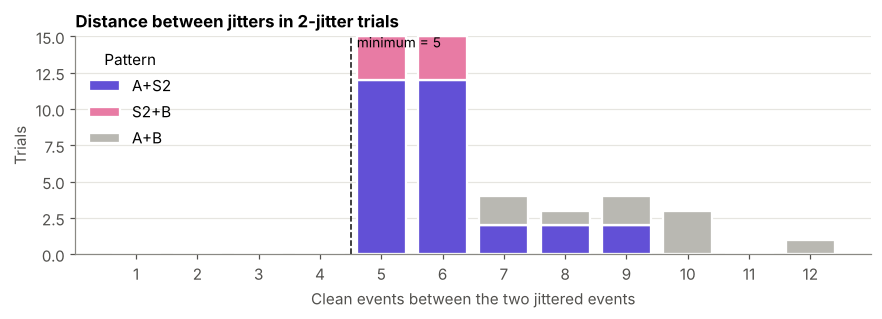

In [22]:
two = df[df.n_jitters == 2]
t = pd.crosstab(two.clean_events_between.astype(int), two.jitter_pattern)
t = t.reindex(range(1, int(t.index.max()) + 1), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.0))
bottom = np.zeros(len(t))
for pat, col in [("A+S2", "#6250d6"), ("S2+B", "#e87ba4"), ("A+B", "#b9b8b2")]:
    if pat in t:
        ax.bar(t.index, t[pat], bottom=bottom, color=col, label=pat, edgecolor="white", linewidth=1.5)
        bottom += t[pat].values
ax.axvline(MIN_EVENTS_BETWEEN - 1 - 0.5, color=INK, ls="--", lw=1)
ax.text(MIN_EVENTS_BETWEEN - 1 - 0.4, bottom.max() * 0.95, "minimum = 5", fontsize=9)
ax.set_xticks(t.index); ax.set_xlabel("Clean events between the two jittered events"); ax.set_ylabel("Trials")
ax.set_title("Distance between jitters in 2-jitter trials", loc="left"); ax.legend(title="Pattern", loc="upper left")
plt.tight_layout(); plt.show()

## 8. Randomization across participants
Every participant has the **same counts** (all checks pass), but a **different item ↔ condition mapping, block placement and order**. Below: 40 simulated participants.
- **8.1** For each 2|4 sentence: how often (out of 40) it received each size×direction at critical I2. A flat-ish map = items are not confounded with jitter levels.
- **8.2** For each 2|4 sentence: in which block its critical I2 trial landed – spread over blocks, so item is not confounded with time in session.
- **8.3** Mean exposure (1st–4th hearing) of critical trials by boundary status per participant – centred on 2.5, no systematic familiarity difference.

✓ 40 participants generated, all pass the balance checks


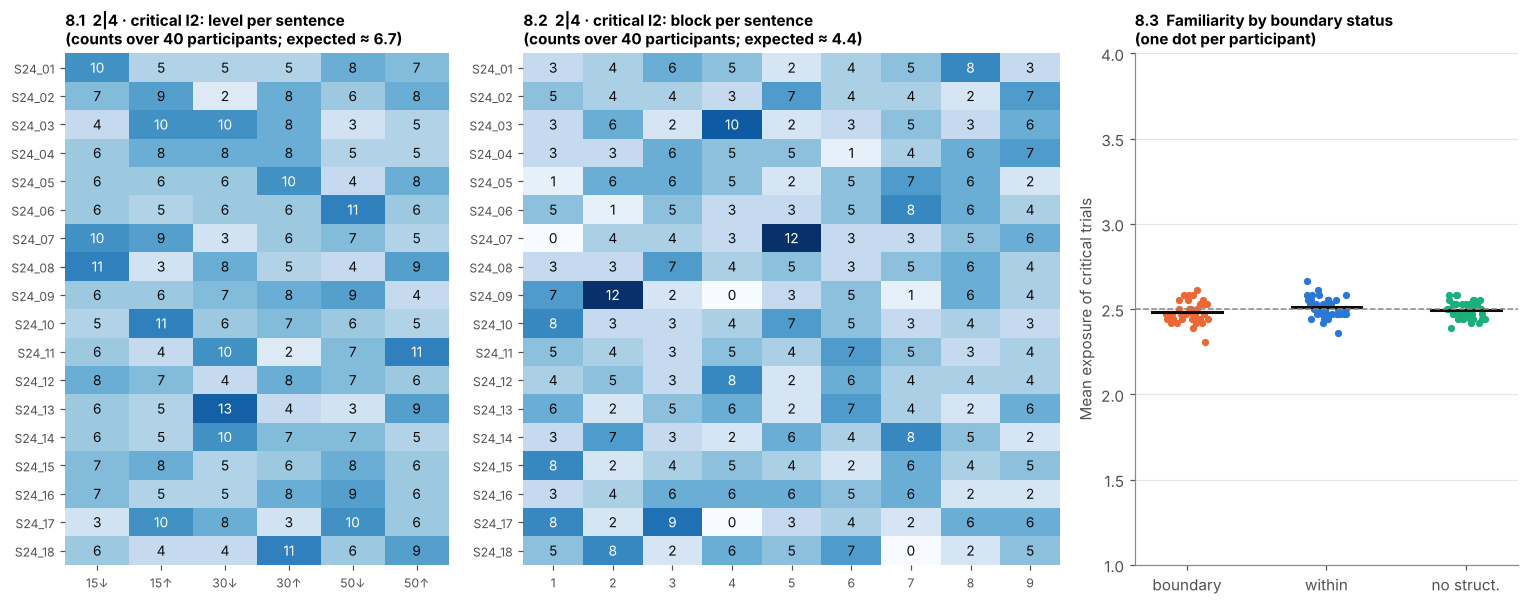

In [23]:
sims = []
for i in range(1, 41):
    sims.append(make_design(f"P{i:02d}", "speech" if i % 2 else "acoustic"))
sim = pd.concat(sims, ignore_index=True)
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    for d in sims: check_balance(d)
print(f"✓ {len(sims)} participants generated, all pass the balance checks")

c2 = sim[(sim.sentence_type == "2|4") & (sim.role == "critical_I2")].copy()
c2["level"] = c2.S2_size_ms.astype(int).astype(str) + np.where(c2.S2_direction == "late", "↑", "↓")
levels = [f"{s}{a}" for s in JITTER_SIZES_MS for a in ("↓", "↑")]
fig, axes = plt.subplots(1, 3, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1, 1.4, 1]})
t = pd.crosstab(c2.sentence_id, c2.level).reindex(columns=levels, fill_value=0)
count_heatmap(axes[0], t, "8.1  2|4 · critical I2: level per sentence\n(counts over 40 participants; expected ≈ 6.7)", vmax=16)
t = pd.crosstab(c2.sentence_id, c2.block).reindex(columns=range(1, N_BLOCKS + 1), fill_value=0)
count_heatmap(axes[1], t, "8.2  2|4 · critical I2: block per sentence\n(counts over 40 participants; expected ≈ 4.4)", vmax=12)
ex = (sim[sim.S2_critical].groupby(["participant", "S2_boundary_status"]).exposure.mean().unstack())
ax = axes[2]
for j, s in enumerate(["boundary", "within-phrase", "no structure"]):
    ax.scatter(np.full(len(ex), j) + np.random.default_rng(j).uniform(-0.15, 0.15, len(ex)), ex[s], s=14,
               color={"boundary": "#eb6834", "within-phrase": "#2a78d6", "no structure": "#1baf7a"}[s])
    ax.plot([j - 0.25, j + 0.25], [ex[s].mean()] * 2, color=INK, lw=2)
ax.axhline(2.5, color="#8a8984", ls="--", lw=1)
ax.set_xticks(range(3), ["boundary", "within", "no struct."]); ax.set_ylim(1, 4)
ax.set_ylabel("Mean exposure of critical trials"); ax.set_title("8.3  Familiarity by boundary status\n(one dot per participant)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 9. Save the table

In [24]:
Path(OUTPUT_DIR).mkdir(exist_ok=True)
path = Path(OUTPUT_DIR) / f"design_{PARTICIPANT_ID}_{GROUP}.csv"
df.to_csv(path, index=False)
print("Saved", path)

Saved design_tables/design_P01_speech.csv


## 10. (Optional) Tables for all participants
Uncomment to write one CSV per participant (own seed each → different mapping and order, same counts).

In [25]:
# for i in range(1, 41):
#     pid = f"P{i:02d}"
#     grp = "speech" if i % 2 else "acoustic"
#     d = make_design(pid, grp)
#     check_balance(d)
#     d.to_csv(Path(OUTPUT_DIR) / f"design_{pid}_{grp}.csv", index=False)